# Job Offer Acceptance Prediction: Model Training


In [52]:
# REQUIRED LIBRARIES

import os
import time
import json
import hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV,
    GridSearchCV
)
from sklearn.preprocessing import (
    LabelEncoder,
    StandardScaler,
    OneHotEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

plt.style.use('ggplot')
print('All required libraries imported successfully!')

All required libraries imported successfully!


In [53]:
# LOADING DATASET & DROPPING UNWANTED / NOISY FEATURES

data_path = '../dataset/job_offer_acceptance_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'dataset/job_offer_acceptance_dataset.csv'

df_raw = pd.read_csv(data_path)
print(f'Raw Dataset Loaded. Initial Shape: {df_raw.shape}')

# Dropping the 11 noisy/unwanted features and non-predictive metadata
features_to_drop = [
    'candidate_id', 'major', 'university_tier', 'city', 'education_level',
    'kaggle_score', 'linkedin_connections', 'internship_count',
    'github_repositories', 'hackathons_participated', 'leadership_experience',
    'company_industry', 'publications_count', 'application_month', 'application_year'
]

df = df_raw.drop(columns=[c for c in features_to_drop if c in df_raw.columns])
print(f'Cleaned Dataset Shape after dropping noisy features: {df.shape}')
print('Active Feature Columns:', df.columns.tolist())
df.head()

Raw Dataset Loaded. Initial Shape: (200000, 28)
Cleaned Dataset Shape after dropping noisy features: (200000, 13)
Active Feature Columns: ['age', 'gender', 'country', 'years_experience', 'expected_salary_usd', 'offered_salary_usd', 'remote_preference', 'relocation_willingness', 'company_size', 'company_rating', 'offer_accepted', 'salary_offer_gap_usd', 'offer_to_expected_salary_ratio']


,age,gender,country,years_experience,expected_salary_usd,offered_salary_usd,remote_preference,relocation_willingness,company_size,company_rating,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
0,49,Other,Singapore,0.7,55304,64041,Onsite,Yes,Startup,2.7,0,8737,1.1580
1,29,Female,India,2.3,73673,87639,Remote,Yes,Startup,4.5,0,13966,1.1896
2,21,Other,Japan,0.9,55910,52128,Onsite,No,Medium,3.7,0,-3782,0.9324
3,35,Female,Canada,4.7,78573,92941,Hybrid,No,Enterprise,3.9,1,14368,1.1829
4,22,Male,Germany,1.2,51525,57365,Onsite,Yes,Enterprise,4.1,0,5840,1.1133



## 1. FEATURE ENGINEERING & FEATURE SELECTION


In [54]:
# FEATURE ENGINEERING IMPLEMENTATION

df_fe = df.copy()
df_fe['salary_hike_pct'] = ((df_fe['offered_salary_usd'] - df_fe['expected_salary_usd']) / df_fe['expected_salary_usd'].replace(0, 1)) * 100
df_fe['exp_to_age_ratio'] = df_fe['years_experience'] / df_fe['age'].replace(0, 1)

target_col = 'offer_accepted' if 'offer_accepted' in df_fe.columns else 'Offer_Accepted'
print(f'Feature Engineering complete. Total features: {df_fe.shape[1] - 1}')
df_fe[['salary_offer_gap_usd', 'offer_to_expected_salary_ratio', 'salary_hike_pct', 'exp_to_age_ratio']].head()

Feature Engineering complete. Total features: 14


,salary_offer_gap_usd,offer_to_expected_salary_ratio,salary_hike_pct,exp_to_age_ratio
0,8737,1.1580,15.798134,0.014286
1,13966,1.1896,18.956741,0.079310
2,-3782,0.9324,-6.764443,0.042857
3,14368,1.1829,18.286180,0.134286
4,5840,1.1133,11.334304,0.054545


Features Ranked by ANOVA F-Score:
                           Feature  ANOVA_F_Score        P_Value
0               offered_salary_usd   37185.953795   0.000000e+00
1              expected_salary_usd   29446.099263   0.000000e+00
2                 years_experience   25888.580449   0.000000e+00
3                 exp_to_age_ratio   21715.076392   0.000000e+00
4             salary_offer_gap_usd   14923.033534   0.000000e+00
5   offer_to_expected_salary_ratio    6776.225573   0.000000e+00
6                  salary_hike_pct    6776.218297   0.000000e+00
7                   company_rating    1306.050059  4.590692e-285
8                remote_preference    1178.317076  1.777089e-257
9                     company_size       2.124011   1.450079e-01
10                          gender       1.377518   2.405258e-01
11                         country       0.400628   5.267659e-01
12                             age       0.247016   6.191843e-01
13          relocation_willingness       0.006789   9.34

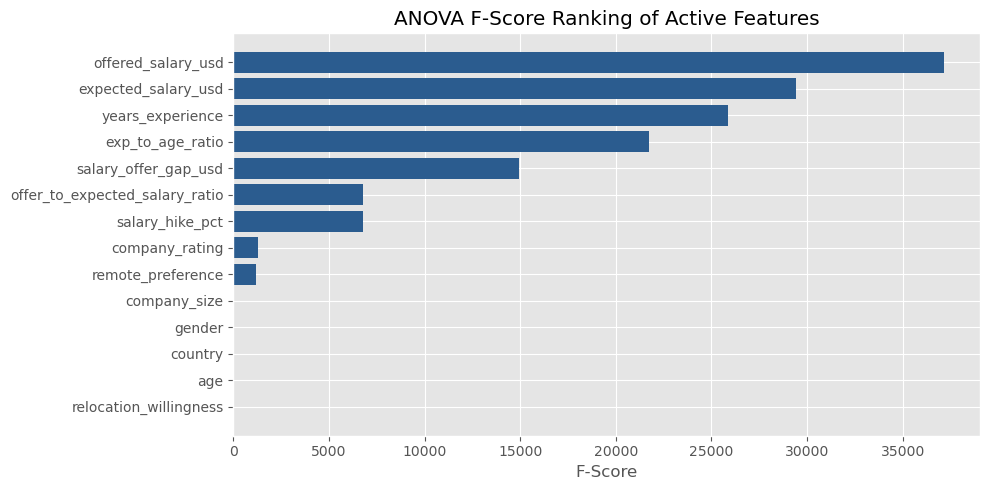

In [55]:
# FEATURE SELECTION RANKING WITH SELECTKBEST (ANOVA F-TEST)

df_temp = df_fe.copy()
for col in df_temp.select_dtypes(include=['object']).columns:
    df_temp[col] = LabelEncoder().fit_transform(df_temp[col].astype(str))

X_fs = df_temp.drop(target_col, axis=1)
y_fs = df_temp[target_col]

kbest = SelectKBest(score_func=f_classif, k='all')
kbest.fit(X_fs, y_fs)

fs_ranking = pd.DataFrame({
    'Feature': X_fs.columns,
    'ANOVA_F_Score': kbest.scores_,
    'P_Value': kbest.pvalues_
}).sort_values('ANOVA_F_Score', ascending=False).reset_index(drop=True)

print('Features Ranked by ANOVA F-Score:')
print(fs_ranking)

plt.figure(figsize=(10, 5))
plt.barh(fs_ranking['Feature'][::-1], fs_ranking['ANOVA_F_Score'][::-1], color='#2b5c8f')
plt.title('ANOVA F-Score Ranking of Active Features')
plt.xlabel('F-Score')
plt.tight_layout()
plt.show()

In [56]:
# ENCODING CATEGORICAL FEATURES & SAVING ENCODERS

models_dir = '../models' if os.path.exists('../models') else 'models'
os.makedirs(models_dir, exist_ok=True)

encoders = {}
categorical_cols = df_fe.select_dtypes(include=['object']).columns.tolist()

for col in categorical_cols:
    if col == target_col:
        continue
    le = LabelEncoder()
    df_fe[col] = le.fit_transform(df_fe[col].astype(str))
    encoders[col] = le

joblib.dump(encoders, os.path.join(models_dir, 'encoders.pkl'))
print(f'Encoded {len(encoders)} categorical columns and saved encoders to models/encoders.pkl')

Encoded 5 categorical columns and saved encoders to models/encoders.pkl


In [57]:
# FEATURE SCALING & SAVING SCALER

X = df_fe.drop(columns=[target_col])
y = df_fe[target_col]
feature_names = X.columns.tolist()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

joblib.dump(scaler, os.path.join(models_dir, 'scaler.pkl'))
joblib.dump(feature_names, os.path.join(models_dir, 'feature_names.pkl'))
print(f'StandardScaler fitted and saved. Total active features: {len(feature_names)}')
print('Feature list:', feature_names)

StandardScaler fitted and saved. Total active features: 14
Feature list: ['age', 'gender', 'country', 'years_experience', 'expected_salary_usd', 'offered_salary_usd', 'remote_preference', 'relocation_willingness', 'company_size', 'company_rating', 'salary_offer_gap_usd', 'offer_to_expected_salary_ratio', 'salary_hike_pct', 'exp_to_age_ratio']



## 2. STRATIFIED K-FOLD CROSS-VALIDATION


In [58]:
# 5-FOLD STRATIFIED K-FOLD CROSS-VALIDATION

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Use a 40,000 sample slice for fast and robust cross-validation
sample_idx = np.random.RandomState(42).choice(len(X_scaled), size=min(40000, len(X_scaled)), replace=False)
X_cv = X_scaled[sample_idx]
y_cv = y.iloc[sample_idx]

# Scale positive weight for XGBoost in CV
cv_scale_weight = float((len(y_cv) - sum(y_cv)) / sum(y_cv))

cv_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=8, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, class_weight='balanced'),
    'XGBoost': XGBClassifier(n_estimators=60, max_depth=5, scale_pos_weight=cv_scale_weight, random_state=42, eval_metric='logloss')
}

cv_summary = []
for name, model in cv_models.items():
    t0 = time.time()
    scores = cross_val_score(model, X_cv, y_cv, cv=skf, scoring='f1')
    acc_scores = cross_val_score(model, X_cv, y_cv, cv=skf, scoring='accuracy')
    t1 = time.time()
    
    cv_summary.append({
        'Model': name,
        'Mean F1 Score (%)': round(scores.mean() * 100, 2),
        'F1 Std Dev (%)': round(scores.std() * 100, 2),
        'Mean Accuracy (%)': round(acc_scores.mean() * 100, 2),
        'CV Time (s)': round(t1 - t0, 2)
    })

cv_df = pd.DataFrame(cv_summary).sort_values('Mean F1 Score (%)', ascending=False).reset_index(drop=True)
print('Stratified 5-Fold Cross-Validation Benchmark:')
print(cv_df)

Stratified 5-Fold Cross-Validation Benchmark:
                 Model  Mean F1 Score (%)  F1 Std Dev (%)  Mean Accuracy (%)  \
0              XGBoost              57.96            0.56              69.66   
1        Random Forest              57.81            0.71              70.92   
2  Logistic Regression              57.75            0.69              70.16   
3        Decision Tree              57.11            0.41              69.22   

   CV Time (s)  
0         9.83  
1        25.12  
2         0.67  
3         3.30  



## 3. TRAIN-TEST SPLIT & BASELINE MODEL EVALUATIONS


In [59]:
# STRATIFIED 80/20 TRAIN-TEST SPLIT & CLASS WEIGHT CALCULATION

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scale_pos_weight = float((len(y_train) - sum(y_train)) / sum(y_train))
print(f'Train samples: {len(X_train):,}, Test samples: {len(X_test):,}')
print(f'Computed scale_pos_weight: {scale_pos_weight:.3f}')

Train samples: 160,000, Test samples: 40,000
Computed scale_pos_weight: 2.015


In [60]:
# FITTING BASELINE CLASSIFIERS ON FULL TRAIN SPLIT

baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=10, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, class_weight='balanced', n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
}

comparison_results = []
fitted_models = {}
y_preds = {}

for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]
    
    fitted_models[name] = model
    y_preds[name] = preds
    
    comparison_results.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, preds) * 100, 2),
        'Precision (%)': round(precision_score(y_test, preds, zero_division=0) * 100, 2),
        'Recall (%)': round(recall_score(y_test, preds, zero_division=0) * 100, 2),
        'F1 Score (%)': round(f1_score(y_test, preds, zero_division=0) * 100, 2),
        'ROC-AUC (%)': round(roc_auc_score(y_test, probs) * 100, 2)
    })

baseline_df = pd.DataFrame(comparison_results).sort_values('F1 Score (%)', ascending=False).reset_index(drop=True)
print('Baseline Model Performance on Test Split:')
print(baseline_df)

Baseline Model Performance on Test Split:
                 Model  Accuracy (%)  Precision (%)  Recall (%)  F1 Score (%)  \
0              XGBoost         70.07          54.03       65.46         59.19   
1        Random Forest         70.82          55.39       61.82         58.43   
2  Logistic Regression         69.91          54.01       62.36         57.89   
3        Decision Tree         68.64          52.20       64.69         57.78   

   ROC-AUC (%)  
0        75.90  
1        75.74  
2        75.01  
3        74.22  


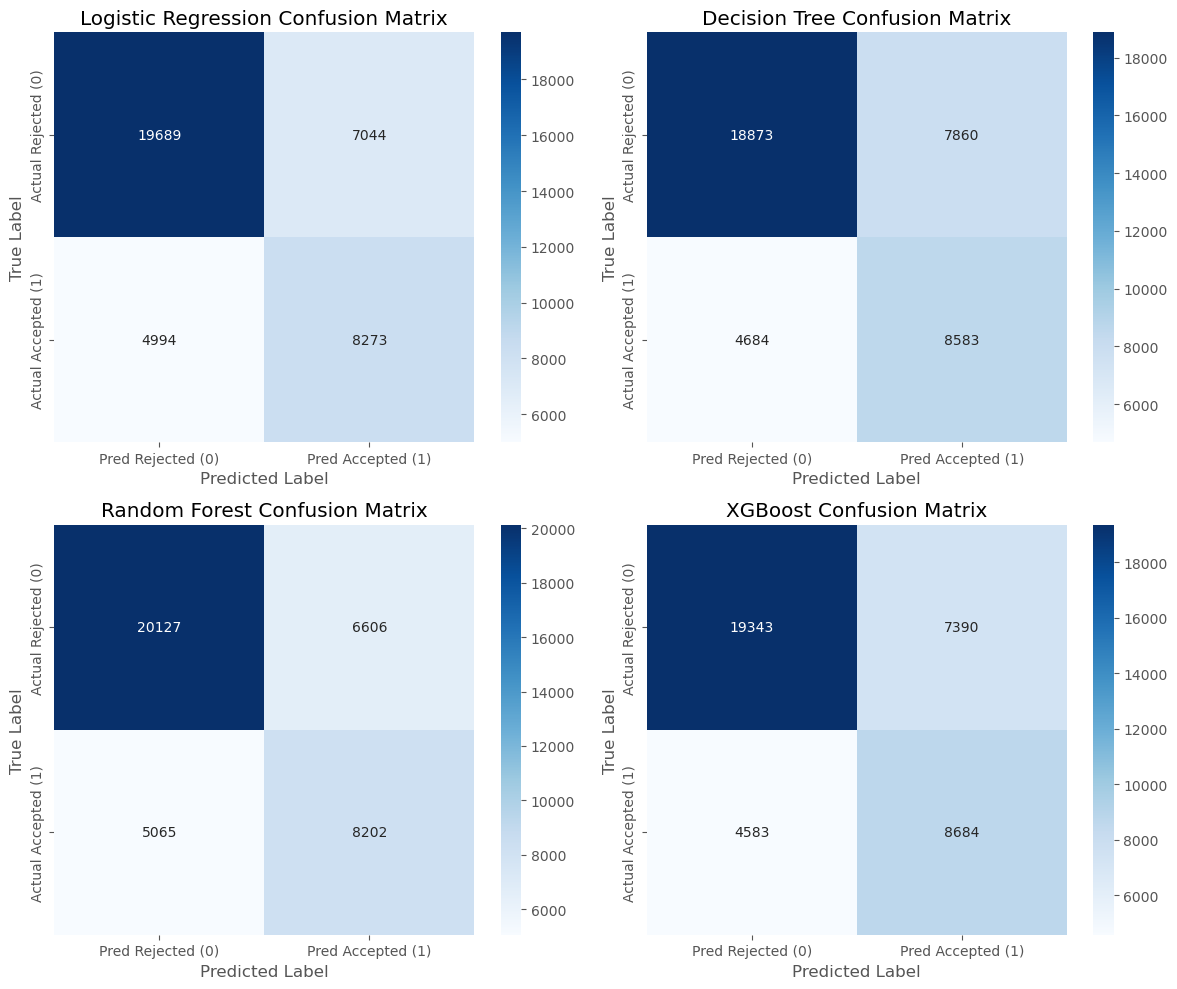

In [61]:
# CONFUSION MATRICES FOR ALL BASELINE MODELS

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, preds) in enumerate(y_preds.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Pred Rejected (0)', 'Pred Accepted (1)'],
                yticklabels=['Actual Rejected (0)', 'Actual Accepted (1)'])
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_ylabel('True Label')
    axes[i].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()


## 4. HYPERPARAMETER TUNING: RANDOMIZEDSEARCHCV & GRIDSEARCHCV


In [62]:
# STAGE 1: RANDOMIZEDSEARCHCV ON XGBOOST

param_distributions = {
    'n_estimators': [80, 100, 120, 150],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.03, 0.05, 0.08, 0.12],
    'subsample': [0.8, 0.9, 1.0],
    'colsample_bytree': [0.8, 0.9, 1.0]
}

# Tune on a 25,000 sample representative slice for fast convergence
tune_idx = np.random.RandomState(42).choice(len(X_train), size=min(25000, len(X_train)), replace=False)
X_tune = X_train[tune_idx]
y_tune = y_train.iloc[tune_idx]

base_xgb = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

random_search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_distributions,
    n_iter=8,
    scoring='f1',
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

t0 = time.time()
random_search.fit(X_tune, y_tune)
t1 = time.time()

print(f'RandomizedSearchCV completed in {t1 - t0:.2f}s')
print('Best Hyperparameters found by RandomizedSearchCV:')
for k, v in random_search.best_params_.items():
    print(f'  - {k}: {v}')
print(f'Best Cross-Validation F1: {random_search.best_score_ * 100:.2f}%')

Fitting 3 folds for each of 8 candidates, totalling 24 fits
RandomizedSearchCV completed in 24.66s
Best Hyperparameters found by RandomizedSearchCV:
  - subsample: 0.8
  - n_estimators: 120
  - max_depth: 4
  - learning_rate: 0.03
  - colsample_bytree: 1.0
Best Cross-Validation F1: 58.47%


In [63]:
# STAGE 2: GRIDSEARCHCV FINE-TUNING

best_depth = random_search.best_params_['max_depth']
best_lr = random_search.best_params_['learning_rate']

param_grid = {
    'max_depth': [best_depth, best_depth + 1],
    'learning_rate': [max(0.02, best_lr - 0.02), best_lr, best_lr + 0.02],
    'n_estimators': [100, 120]
}

grid_search = GridSearchCV(
    estimator=base_xgb,
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1,
    verbose=1
)

t0 = time.time()
grid_search.fit(X_tune, y_tune)
t1 = time.time()

print(f'GridSearchCV completed in {t1 - t0:.2f}s')
print('Final Optimized Hyperparameters:')
for k, v in grid_search.best_params_.items():
    print(f'  - {k}: {v}')
print(f'Optimized Cross-Validation F1: {grid_search.best_score_ * 100:.2f}%')

Fitting 3 folds for each of 12 candidates, totalling 36 fits
GridSearchCV completed in 31.01s
Final Optimized Hyperparameters:
  - learning_rate: 0.05
  - max_depth: 4
  - n_estimators: 100
Optimized Cross-Validation F1: 58.30%


In [64]:
# EVALUATING TUNED MODEL ON TEST DATASET

best_xgb_model = grid_search.best_estimator_
best_xgb_model.fit(X_train, y_train)

tuned_preds = best_xgb_model.predict(X_test)
tuned_probs = best_xgb_model.predict_proba(X_test)[:, 1]

print('--- Tuned XGBoost Classification Report ---')
print(classification_report(y_test, tuned_preds, target_names=['Rejected (0)', 'Accepted (1)']))
print(f'Final Test Accuracy: {accuracy_score(y_test, tuned_preds) * 100:.2f}%')
print(f'Final Test F1-Score: {f1_score(y_test, tuned_preds) * 100:.2f}%')
print(f'Final Test ROC-AUC:  {roc_auc_score(y_test, tuned_probs) * 100:.2f}%')

--- Tuned XGBoost Classification Report ---
              precision    recall  f1-score   support

Rejected (0)       0.81      0.73      0.77     26733
Accepted (1)       0.54      0.65      0.59     13267

    accuracy                           0.70     40000
   macro avg       0.67      0.69      0.68     40000
weighted avg       0.72      0.70      0.71     40000

Final Test Accuracy: 70.24%
Final Test F1-Score: 59.06%
Final Test ROC-AUC:  75.97%



## 5. PRODUCTION SCIKIT-LEARN PIPELINE & SERIALIZATION (`pipeline.pkl`)


In [65]:
# CONSTRUCTING THE PRODUCTION PIPELINE

raw_features_df = df_fe.drop(columns=[target_col])
cat_cols = ['gender', 'country', 'remote_preference', 'relocation_willingness', 'company_size']
num_cols = [c for c in raw_features_df.columns if c not in cat_cols]

# Construct preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Production Pipeline
production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=grid_search.best_params_['n_estimators'],
        max_depth=grid_search.best_params_['max_depth'],
        learning_rate=grid_search.best_params_['learning_rate'],
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    ))
])

print('Production Pipeline Architecture:')
print(production_pipeline)

Production Pipeline Architecture:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'years_experience',
                                                   'expected_salary_usd',
                                                   'offered_salary_usd',
                                                   'company_rating',
                                                   'salary_offer_gap_usd',
                                                   'offer_to_expected_salary_ratio',
                                                   'salary_hike_pct',
                                                   'exp_to_age_ratio']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                             

In [66]:
# TRAINING & EVALUATING PIPELINE ON RAW DATA

X_raw = df_fe.drop(columns=[target_col])
y_raw = df_fe[target_col]

X_raw_train, X_raw_test, y_raw_train, y_raw_test = train_test_split(
    X_raw, y_raw, test_size=0.20, random_state=42, stratify=y_raw
)

print('Fitting End-to-End Pipeline...')
production_pipeline.fit(X_raw_train, y_raw_train)

pipe_preds = production_pipeline.predict(X_raw_test)
pipe_probs = production_pipeline.predict_proba(X_raw_test)[:, 1]

print(f'Pipeline Test Accuracy: {accuracy_score(y_raw_test, pipe_preds) * 100:.2f}%')
print(f'Pipeline Test F1 Score: {f1_score(y_raw_test, pipe_preds) * 100:.2f}%')
print(f'Pipeline Test ROC-AUC:  {roc_auc_score(y_raw_test, pipe_probs) * 100:.2f}%')

Fitting End-to-End Pipeline...
Pipeline Test Accuracy: 70.23%
Pipeline Test F1 Score: 59.04%
Pipeline Test ROC-AUC:  75.97%


In [67]:
# SAVING PIPELINE TO pipeline.pkl AND VERIFYING INFERENCE

pipeline_path = os.path.join(models_dir, 'pipeline.pkl')
joblib.dump(production_pipeline, pipeline_path)
print(f'SUCCESS: Pipeline saved to {pipeline_path}')

# Verify loaded pipeline inference
loaded_pipe = joblib.load(pipeline_path)

sample_candidate = pd.DataFrame([{
    'age': 28,
    'gender': 'Male',
    'country': 'United States',
    'years_experience': 6,
    'expected_salary_usd': 90000,
    'offered_salary_usd': 115000,
    'remote_preference': 'Hybrid',
    'relocation_willingness': 'Yes',
    'company_size': 'Large (1000+)',
    'company_rating': 4.6,
    'salary_offer_gap_usd': 25000,
    'offer_to_expected_salary_ratio': 1.28,
    'salary_hike_pct': 27.78,
    'exp_to_age_ratio': 0.214
}])

test_pred = loaded_pipe.predict(sample_candidate)[0]
test_prob = loaded_pipe.predict_proba(sample_candidate)[0][1]

print(f'Sample Candidate Prediction: {"ACCEPTED (1)" if test_pred == 1 else "REJECTED (0)"}')
print(f'Predicted Acceptance Probability: {test_prob * 100:.2f}%')

SUCCESS: Pipeline saved to ../models\pipeline.pkl
Sample Candidate Prediction: ACCEPTED (1)
Predicted Acceptance Probability: 75.59%



## 6. BEST MODEL SELECTION & ARTIFACT PERSISTENCE



In [68]:
# SAVING INDIVIDUAL MODELS & METRICS

prod_models = {
    'logistic': fitted_models['Logistic Regression'],
    'decision_tree': fitted_models['Decision Tree'],
    'random_forest': fitted_models['Random Forest'],
    'xgboost': best_xgb_model
}

for name, mdl in prod_models.items():
    joblib.dump(mdl, os.path.join(models_dir, f'{name}.pkl'))

joblib.dump(best_xgb_model, os.path.join(models_dir, 'best_model.pkl'))

# Export metrics to model_metrics.json
model_names_map = {
    'logistic': 'Logistic Regression',
    'decision_tree': 'Decision Tree',
    'random_forest': 'Random Forest',
    'xgboost': 'XGBoost'
}

metrics_records = []
for m_key, m_name in model_names_map.items():
    m_obj = prod_models[m_key]
    preds = m_obj.predict(X_test)
    probs = m_obj.predict_proba(X_test)[:, 1]
    metrics_records.append({
        'Model': m_name,
        'Accuracy': round(accuracy_score(y_test, preds) * 100, 2),
        'Precision': round(precision_score(y_test, preds, zero_division=0) * 100, 2),
        'Recall': round(recall_score(y_test, preds, zero_division=0) * 100, 2),
        'F1 Score': round(f1_score(y_test, preds, zero_division=0) * 100, 2),
        'ROC-AUC': round(roc_auc_score(y_test, probs) * 100, 2)
    })

data_hash = hashlib.sha256(open(data_path, 'rb').read()).hexdigest()
final_metrics = {
    'dataset_sha256': data_hash,
    'models': metrics_records
}

with open(os.path.join(models_dir, 'model_metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(final_metrics, f, indent=2)

print('All model artifacts and model_metrics.json updated successfully!')

All model artifacts and model_metrics.json updated successfully!
